# **# 3) Evaluating Model**

Purpose: Script to create visuals for forecast, evaluate and plot error metrics, and either reject and fail to reject null hypotheses.

Languages: Python 3

IDE: Google Colab, file is a Jupiter Notebook notebook document (.ipynb)

Inputs: monthly_oil_gas_prices.csv, evaluation_metrics.csv, forecasts_comparison.csv, multi_horizon_comparison.csv.

Outputs: walk_forward_forecasts.png: actual vs. forecast gas prices for each model, absolute_errors_over_time.png,
absolute_errors_boxplot.png, bias_and_residuals_comparison.png, rmse_comparison.png, rmse_comparison.png

Packages: pandas, numpy, matplotlib, warnings, statsmodels, seaborn, sci-kit learn

Run: python SCRIPTS/2_Build_Model.ipynb (from the repo root) first. Then this script.

Order: Run Third




In [35]:
#importing packages and reading in outputs of previous scripts and cleans and differenced data.
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import warnings
warnings.filterwarnings("ignore")

! rm -rf DS_4002_Project_2
! git clone https://github.com/oliviapang/DS_4002_Project_2
data = pd.read_csv('/content/DS_4002_Project_2/DATA/cleaned_differenced_data.csv')
display(data.head())
evaluations = pd.read_csv('/content/DS_4002_Project_2/OUTPUT/evaluation_metrics.csv')
fc = pd.read_csv('/content/DS_4002_Project_2/OUTPUT/forecasts_comparison.csv', parse_dates=['date'], index_col='date')
display(evaluations.head())
display(fc.head())

Cloning into 'DS_4002_Project_2'...
remote: Enumerating objects: 250, done.
remote: Counting objects: 100% (125/125), done.
remote: Compressing objects: 100% (85/85), done.
remote: Total 250 (delta 92), reused 40 (delta 40), pack-reused 125 (from 1)
Receiving objects: 100% (250/250), 3.91 MiB | 27.03 MiB/s, done.
Resolving deltas: 100% (120/120), done.


,Date,Log_Gas_Price,Log_Oil_Price,Log_Gas_Price_Diff,Log_Oil_Price_Diff
0,1990-08-01,0.197210,NaN,NaN,NaN
1,1990-09-01,0.229523,3.286759,0.032313,NaN
2,1990-10-01,0.289231,3.511769,0.059708,0.225011
3,1990-11-01,0.280657,3.588230,-0.008573,0.076461
4,1990-12-01,0.293416,3.486457,0.012758,-0.101773


,Unnamed: 0,Naive,SARIMA,SARIMAX
0,MAE,0.141983,0.123565,0.125202
1,RMSE,0.229863,0.199123,0.186735
2,MAPE (%),3.839523,3.386407,3.424098


,actual,sarima,sarimax,naive
date,,,,
2020-01-01,2.54775,2.585608,2.641090,2.55500
2020-02-01,2.44200,2.560468,2.550451,2.54775
2020-03-01,2.23420,2.489020,2.435344,2.44200
2020-04-01,1.84050,2.209534,1.901790,2.23420
2020-05-01,1.86950,1.751130,1.523842,1.84050


In [36]:
#Analysis Plan (Step 4)
# Calculating the evaluation metrics (MAE, RMSE, MAPE)
def calculate_metrics(actual, predicted, name):
    mae = np.mean(np.abs(actual - predicted))
    rmse = np.sqrt(np.mean((actual - predicted)**2))
    mape = np.mean(np.abs((actual - predicted) / actual)) * 100
    return pd.Series({"MAE": mae, "RMSE": rmse, "MAPE (%)": mape}, name=name)

metrics_naive = calculate_metrics(fc['actual'], fc['naive'], 'Naive')
metrics_sarima = calculate_metrics(fc['actual'], fc['sarima'], 'SARIMA')
metrics_sarimax = calculate_metrics(fc['actual'], fc['sarimax'], 'SARIMAX')
#Creating dataframe
metrics_df = pd.concat([metrics_naive, metrics_sarima, metrics_sarimax], axis=1)
display(metrics_df)

,Naive,SARIMA,SARIMAX
MAE,0.151508,0.135714,0.132786
RMSE,0.219824,0.192198,0.178372
MAPE (%),4.512469,4.084105,3.974821


In [37]:
#Analysis plan step 5
#Conducting the Diebold-Mariano Test Function
#Content adapted from Anthropic. (2026). Claude (Opus 5.5 version) [Large language model]. https://claude.ai

#Creating function to execute diebold_mariano_test
def diebold_mariano_test(actual, pred1, pred2, h=1, power=2):
    actual = np.asarray(actual)
    pred1 = np.asarray(pred1)
    pred2 = np.asarray(pred2)
    e1 = actual - pred1
    e2 = actual - pred2

    # Loss differential series
    d = np.abs(e1)**power - np.abs(e2)**power
    mean_d = np.mean(d)
    n = len(d)

    # Autocovariance up to lag h-1
    cov_d = np.zeros(h)
    for lag in range(h):
        if lag == 0:
            cov_d[lag] = np.var(d, ddof=0)
        else:
            cov_d[lag] = np.mean((d[lag:] - mean_d) * (d[:-lag] - mean_d))

    # Spectral density estimate
    var_d = cov_d[0] + 2 * np.sum(cov_d[1:])

    # DM statistic
    dm_stat = mean_d / np.sqrt(var_d / n)

    # Two-sided p-value using the standard normal distribution
    from scipy.stats import norm
    p_value = 2 * (1 - norm.cdf(np.abs(dm_stat)))

    return dm_stat, p_value

# Execute Diebold-Mariano test between SARIMA and SARIMAX
dm_stat, p_val_two_sided = diebold_mariano_test(fc['actual'], fc['sarima'], fc['sarimax'], h=1, power=2)
p_val = p_val_two_sided / 2 if dm_stat > 0 else 1 - p_val_two_sided / 2
print(f"Diebold-Mariano Statistic: {dm_stat:.4f}")
print(f"Two-sided p-value: {p_val_two_sided:.4f}")
print(f"One-sided p-value (Ha: SARIMAX more accurate): {p_val:.4f}")
if p_val < 0.05:
    print("Since the one-sided p-value is less than 0.05, SARIMAX is significantly more accurate than SARIMA.")
else:
    print("Since the one-sided p-value is greater than or equal to 0.05, SARIMAX is not significantly more accurate than SARIMA.")

Diebold-Mariano Statistic: 0.9747
Two-sided p-value: 0.3297
One-sided p-value (Ha: SARIMAX more accurate): 0.1649
Since the one-sided p-value is greater than or equal to 0.05, SARIMAX is not significantly more accurate than SARIMA.


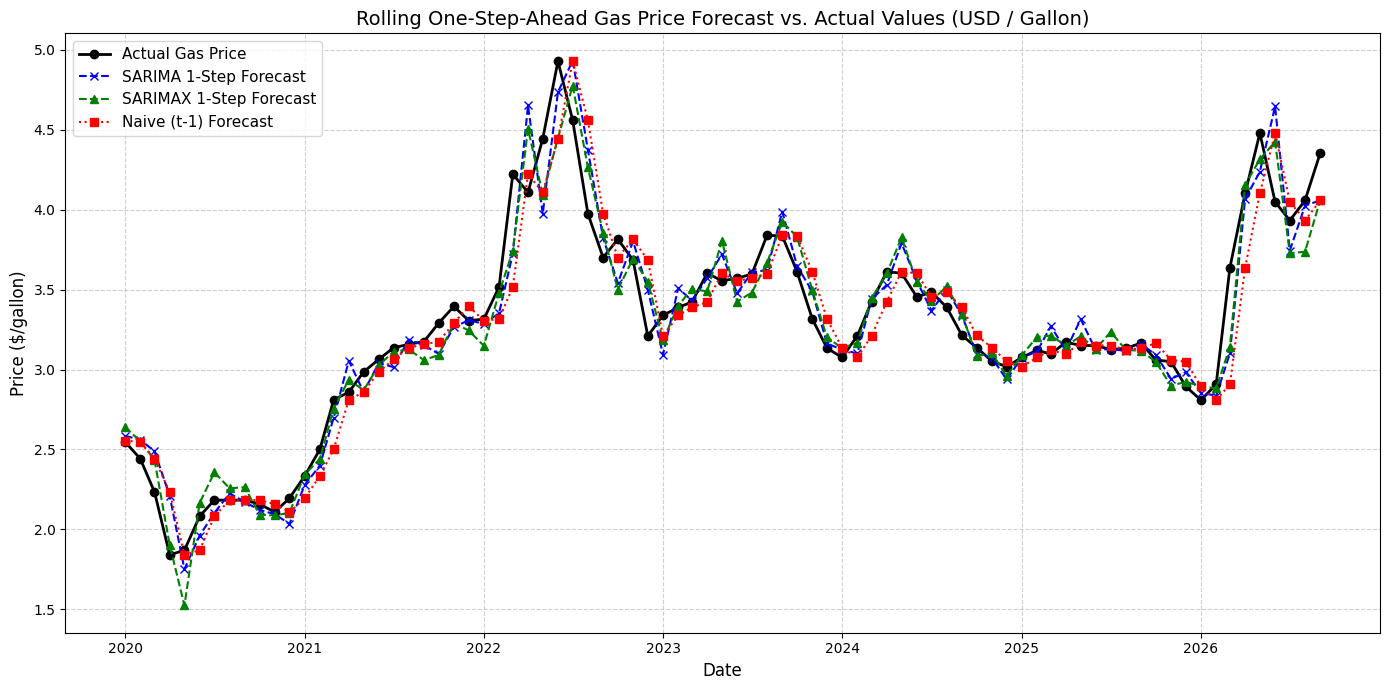

In [38]:
#Producing visualizations of these Forecasts (Walk-Forward)
plt.figure(figsize=(14, 7))
plt.plot(fc.index, fc['actual'], label='Actual Gas Price', color='black', marker='o', linewidth=2)
plt.plot(fc.index, fc['sarima'], label='SARIMA 1-Step Forecast', color='blue', linestyle='--', marker='x')
plt.plot(fc.index, fc['sarimax'], label='SARIMAX 1-Step Forecast', color='green', linestyle='--', marker='^')
plt.plot(fc.index, fc['naive'], label='Naive (t-1) Forecast', color='red', linestyle=':', marker='s')

plt.title('Rolling One-Step-Ahead Gas Price Forecast vs. Actual Values (USD / Gallon)', fontsize=14)
plt.xlabel('Date', fontsize=12)

# Ensure output directory exists
import os
os.makedirs('/content/DS_4002_Project_2/OUTPUT', exist_ok=True)

plt.ylabel('Price ($/gallon)', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('/content/DS_4002_Project_2/OUTPUT/walk_forward_forecasts.png', dpi=300)
plt.show()

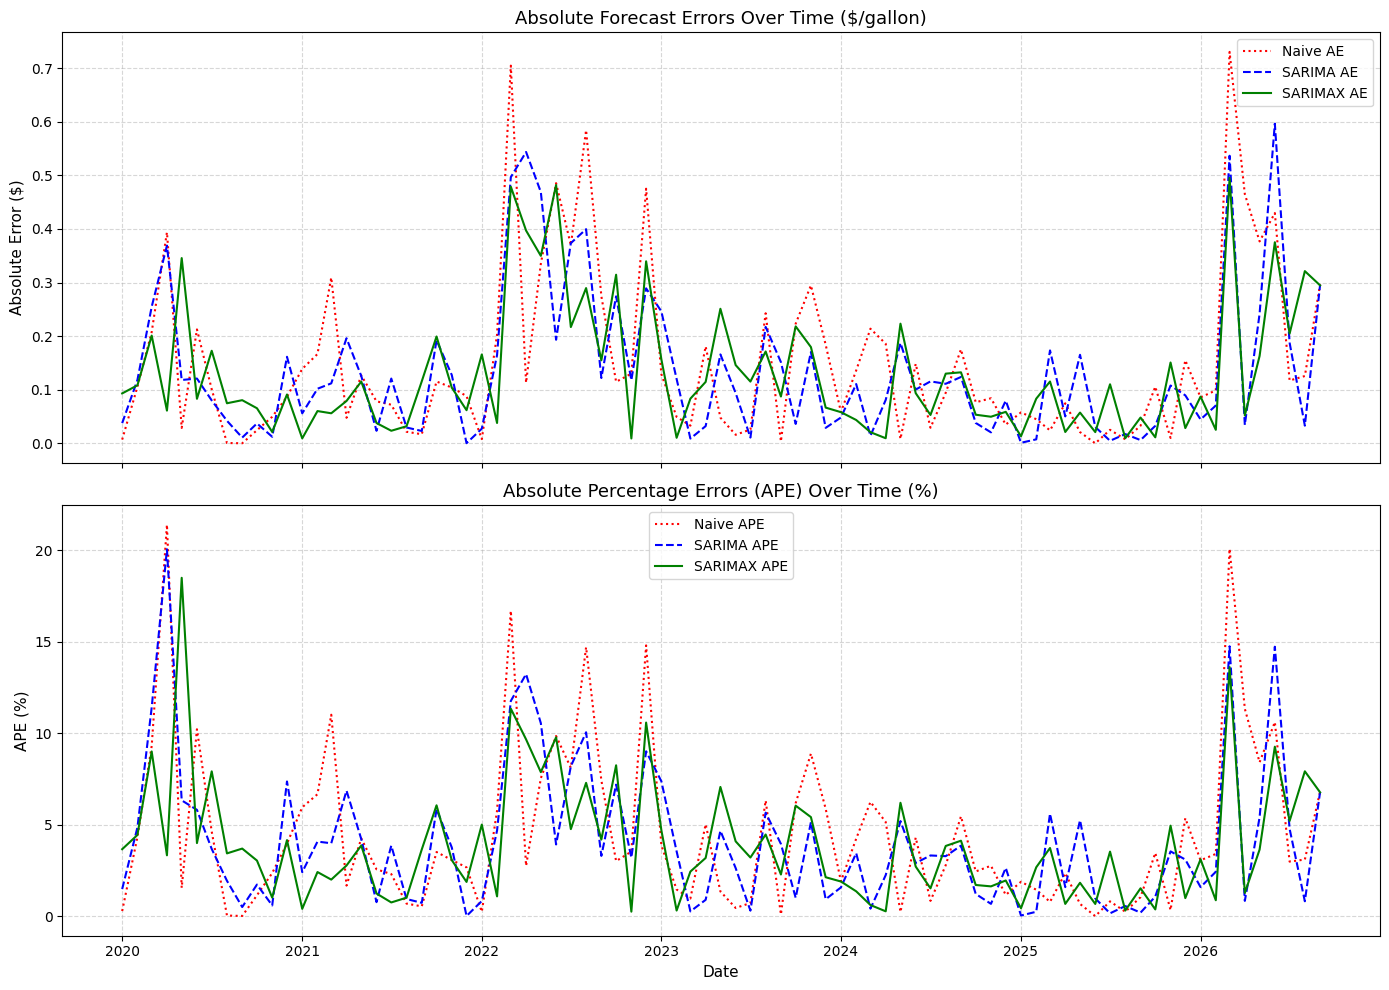

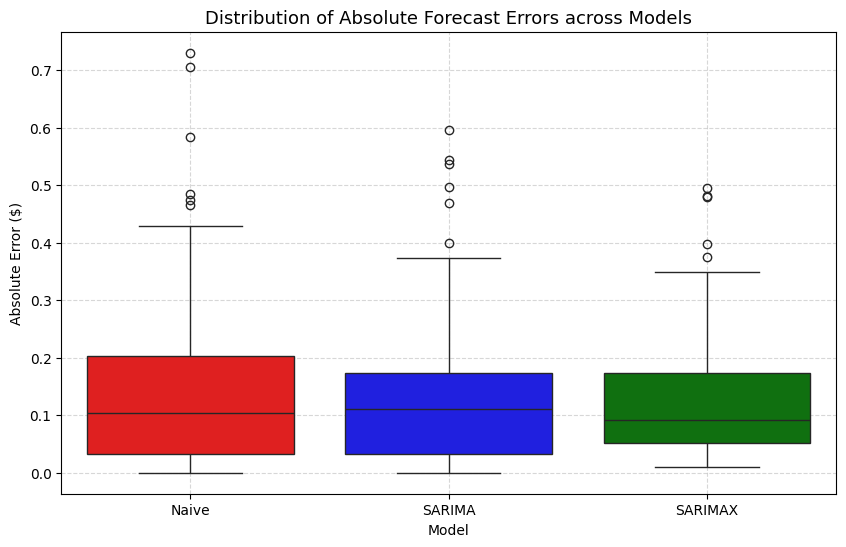

In [30]:
#Analysis Plan Step 6: Visualizations of Error Metrics
#Content adapted from Google. (2026). Gemini [Large language model]. https://gemini.google.com
#Calculate Absolute Errors (AE) and Absolute Percentage Errors (APE)
error_df = pd.DataFrame(index=fc.index)
error_df['Naive_AE'] = np.abs(fc['actual'] - fc['naive'])
error_df['SARIMA_AE'] = np.abs(fc['actual'] - fc['sarima'])
error_df['SARIMAX_AE'] = np.abs(fc['actual'] - fc['sarimax'])

error_df['Naive_APE'] = (error_df['Naive_AE'] / fc['actual']) * 100
error_df['SARIMA_APE'] = (error_df['SARIMA_AE'] / fc['actual']) * 100
error_df['SARIMAX_APE'] = (error_df['SARIMAX_AE'] / fc['actual']) * 100

# Create a multi-panel visualization
fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

#Absolute Error Over Time
axes[0].plot(error_df.index, error_df['Naive_AE'], label='Naive AE', color='red', linestyle=':')
axes[0].plot(error_df.index, error_df['SARIMA_AE'], label='SARIMA AE', color='blue', linestyle='--')
axes[0].plot(error_df.index, error_df['SARIMAX_AE'], label='SARIMAX AE', color='green', linestyle='-')
axes[0].set_title('Absolute Forecast Errors Over Time ($/gallon)', fontsize=13)
axes[0].set_ylabel('Absolute Error ($)', fontsize=11)
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

#Absolute Percentage Error Over Time
axes[1].plot(error_df.index, error_df['Naive_APE'], label='Naive APE', color='red', linestyle=':')
axes[1].plot(error_df.index, error_df['SARIMA_APE'], label='SARIMA APE', color='blue', linestyle='--')
axes[1].plot(error_df.index, error_df['SARIMAX_APE'], label='SARIMAX APE', color='green', linestyle='-')
axes[1].set_title('Absolute Percentage Errors (APE) Over Time (%)', fontsize=13)
axes[1].set_xlabel('Date', fontsize=11)
axes[1].set_ylabel('APE (%)', fontsize=11)
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('/content/DS_4002_Project_2/OUTPUT/absolute_errors_over_time.png', dpi=300)
plt.show()

# Distribution of Errors
plt.figure(figsize=(10, 6))
ae_melted = error_df[['Naive_AE', 'SARIMA_AE', 'SARIMAX_AE']].melt(var_name='Model', value_name='Absolute Error ($)')
ae_melted['Model'] = ae_melted['Model'].str.replace('_AE', '')
sns.boxplot(data=ae_melted, x='Model', y='Absolute Error ($)', palette=['red', 'blue', 'green'])
plt.title('Distribution of Absolute Forecast Errors across Models', fontsize=13)
plt.grid(True, linestyle='--', alpha=0.5)
plt.savefig('/content/DS_4002_Project_2/OUTPUT/absolute_errors_boxplot.png', dpi=300)
plt.show()

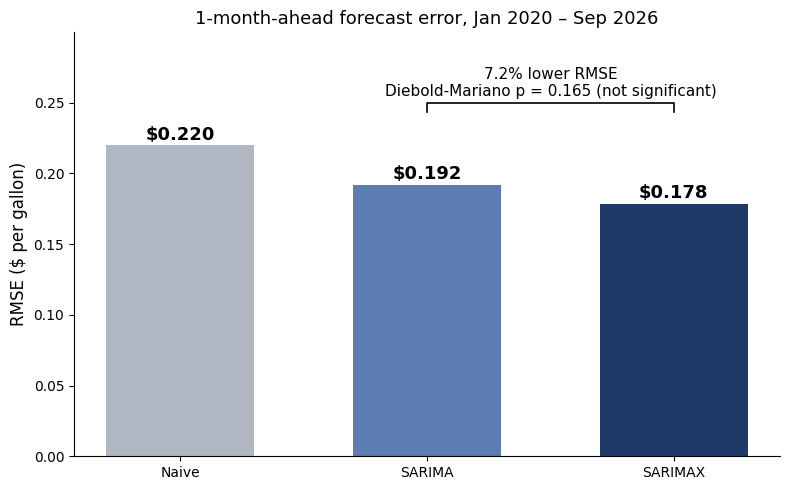

In [31]:
#RMSE by model, with the finish-line result
#Content adapted from Anthropic. (2026). Claude (Opus 5.5 version) [Large language model]. https://claude.ai
rmse = metrics_df.loc['RMSE', ['Naive', 'SARIMA', 'SARIMAX']]
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(rmse.index, rmse.values, color=['#B0B7C3', '#5B7DB1', '#1F3A68'], width=0.6)

# Label each bar with its value
for bar, v in zip(bars, rmse.values):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.004, f'${v:.3f}',
            ha='center', fontsize=13, fontweight='bold')

# Bracket between SARIMA and SARIMAX showing the gap and the DM result
y = rmse.max() + 0.03
ax.plot([1, 1, 2, 2], [y - 0.006, y, y, y - 0.006], color='black', linewidth=1.2)
ax.text(1.5, y + 0.005, '7.2% lower RMSE\nDiebold-Mariano p = 0.165 (not significant)',
        ha='center', fontsize=11)

ax.set_ylabel('RMSE ($ per gallon)', fontsize=12)
ax.set_title('1-month-ahead forecast error, Jan 2020 – Sep 2026', fontsize=13)
ax.set_ylim(0, rmse.max() + 0.08)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('/content/DS_4002_Project_2/OUTPUT/rmse_comparison.png', dpi=300)
plt.show()

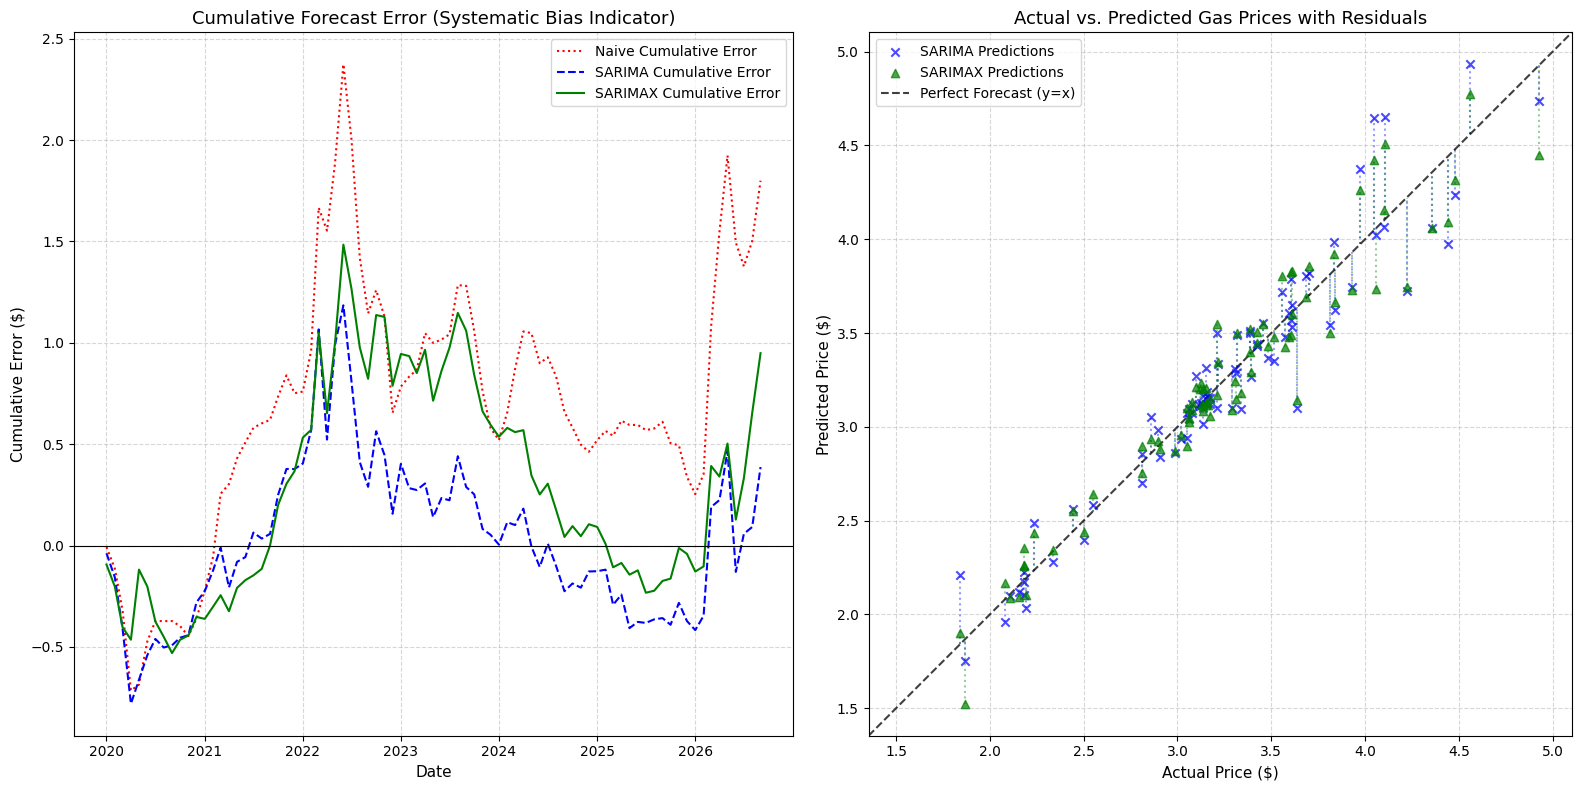

In [32]:
#Further Analysis on error metrics that compare the error of Naive, SARIMA, and SARIMAX models
#Content adapted from Google. (2026). Gemini [Large language model]. https://gemini.google.com
#Cumulative forecast error (Bias)
fc_sorted = fc.sort_index()
cum_error_sarima = (fc_sorted['actual'] - fc_sorted['sarima']).cumsum()
cum_error_sarimax = (fc_sorted['actual'] - fc_sorted['sarimax']).cumsum()
cum_error_naive = (fc_sorted['actual'] - fc_sorted['naive']).cumsum()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))

# Cumulative error over time plot
ax1.plot(fc_sorted.index, cum_error_naive, label='Naive Cumulative Error', color='red', linestyle=':')
ax1.plot(fc_sorted.index, cum_error_sarima, label='SARIMA Cumulative Error', color='blue', linestyle='--')
ax1.plot(fc_sorted.index, cum_error_sarimax, label='SARIMAX Cumulative Error', color='green', linestyle='-')
ax1.axhline(0, color='black', linewidth=0.8, linestyle='-')
ax1.set_title('Cumulative Forecast Error (Systematic Bias Indicator)', fontsize=13)
ax1.set_xlabel('Date', fontsize=11)
ax1.set_ylabel('Cumulative Error ($)', fontsize=11)
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.5)

# Actual vs Predicted Scatter Plot with Residuals
ax2.scatter(fc_sorted['actual'], fc_sorted['sarima'], label='SARIMA Predictions', color='blue', alpha=0.7, marker='x', zorder=3)
ax2.scatter(fc_sorted['actual'], fc_sorted['sarimax'], label='SARIMAX Predictions', color='green', alpha=0.7, marker='^', zorder=3)
# Add y=x identity line representing a perfect forecast
lims = [
    min(ax2.get_xlim()[0], ax2.get_ylim()[0]),
    max(ax2.get_xlim()[1], ax2.get_ylim()[1])
]
# Add visual residuals (vertical lines from the predicted points to the y = x identity line)
for idx, row in fc_sorted.iterrows():
    ax2.vlines(x=row['actual'], ymin=min(row['actual'], row['sarima']), ymax=max(row['actual'], row['sarima']),
               color='blue', linestyle=':', alpha=0.4, zorder=1)

    ax2.vlines(x=row['actual'], ymin=min(row['actual'], row['sarimax']), ymax=max(row['actual'], row['sarimax']),
               color='green', linestyle=':', alpha=0.4, zorder=1)

ax2.plot(lims, lims, 'k--', alpha=0.75, zorder=2, label='Perfect Forecast (y=x)')
ax2.set_xlim(lims)
ax2.set_ylim(lims)
ax2.set_aspect('equal')
ax2.set_xlabel('Actual Price ($)', fontsize=11)
ax2.set_ylabel('Predicted Price ($)', fontsize=11)
ax2.set_title('Actual vs. Predicted Gas Prices with Residuals', fontsize=13)
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('/content/DS_4002_Project_2/OUTPUT/bias_and_residuals_comparison.png', dpi=300)
plt.show()

In [33]:
#Displaying evaluations
# Defining the hypotheses of this analysis
hypotheses = """
List of Hypotheses:
1. Initial Differenced Relationship (In-Sample Coefficient Test):
   - H0: Crude oil price has no linear effect on gasoline prices (coefficient of Log_Oil_Price_Diff is 0).
   - Ha: The lagged crude oil price has a significant linear effect on retail gasoline prices (coefficient is non-zero).

2. Predictive Accuracy (Out-of-Sample Walk-Forward Validation):
   - H0: No significant difference in out-of-sample forecast accuracy between the SARIMA and SARIMAX models.
   - Ha: SARIMAX has significantly lower out-of-sample forecast error than SARIMA (one-sided).
"""
print(hypotheses)

# Evaluating In-Sample relationship
# Using pre-computed results from previous scripts.
oil = pd.read_csv('/content/DS_4002_Project_2/OUTPUT/oil_coefficient.csv')
oil_coef = oil.loc[0, 'coef']
oil_pval = oil.loc[0, 'p_value']

print("In-Sample Coefficient Evaluation:")
print(f"  - Log_Oil_Price_Diff Coef: {oil_coef:.4f}")
print(f"  - p-value: {oil_pval:.4e}")
if oil_pval < 0.05:
    print("Reject the null. Lagged crude oil price is a statistically significant predictor of gas prices.")
else:
    print("Fail to reject the null. Lagged crude oil price is not a statistically significant predictor of gas prices")


List of Hypotheses:
1. Initial Differenced Relationship (In-Sample Coefficient Test):
   - H0: Crude oil price has no linear effect on gasoline prices (coefficient of Log_Oil_Price_Diff is 0).
   - Ha: The lagged crude oil price has a significant linear effect on retail gasoline prices (coefficient is non-zero).

2. Predictive Accuracy (Out-of-Sample Walk-Forward Validation):
   - H0: No significant difference in out-of-sample forecast accuracy between the SARIMA and SARIMAX models.
   - Ha: SARIMAX has significantly lower out-of-sample forecast error than SARIMA (one-sided).

In-Sample Coefficient Evaluation:
  - Log_Oil_Price_Diff Coef: 0.2659
  - p-value: 2.0942e-42
Reject the null. Lagged crude oil price is a statistically significant predictor of gas prices.


In [34]:
# Evaluating Out-of-Sample predictive fifference (Diebold-Mariano test stats)
print("Out-of-Sample Coefficient Evaluation (Diebold-Mariano Test):")
print(f"  - DM Statistic: {dm_stat:.4f}")
print(f"  - One-sided p-value: {p_val:.4f}")
if p_val < 0.05:
    print("Reject the null. SARIMAX is significantly more accurate than SARIMA.")
else:
    print("Fail to reject the null. The difference in out-of-sample forecast accuracy is not statistically significant.")

Out-of-Sample Coefficient Evaluation (Diebold-Mariano Test):
  - DM Statistic: 0.9747
  - One-sided p-value: 0.1649
Fail to reject the null. The difference in out-of-sample forecast accuracy is not statistically significant.
